# Data-Driven SHM of Hospital Real

This Jupyter Notebook demonstrates a data-driven approach to Structural Health Monitoring (SHM) using a real-world dataset from the Hospital Real building in Granada. The primary goal is to understand and correct for the influence of environmental factors—such as temperature and humidity—on structural modal properties, enabling more accurate detection of structural changes.

### Overview

- **Input Features**: Weather data  
  $$
  \mathbf{x} = [T, H]^T
  $$  
  where $T$ is temperature and $H$ is humidity.

- **Quantities of Interest**: Time series of frequencies and mode shapes  
  $$
  \mathbf{y} = [f_1, f_2, f_3, \dots, \boldsymbol{\psi}_1, \boldsymbol{\psi}_2, \boldsymbol{\psi}_3, \dots]
  $$

The input and output datasets are linked by timestamp indices.
Relevant modes and features are selected for modeling.

A **Linear Regression (LinReg)** model is trained on the input features to predict the frequencies and mode shapes.

**Sensitivity analyses** using Sobol indices are performed to understand the global influence of temperature and humidity.

**SHAP (SHapley Additive exPlanations)** values are computed to quantify the local impact of individual features on model predictions.

The **effects** of environmental variables are visualized and interpreted.

Finally, four different models trained on frequencies are compared to see how well they capture and correct for environmental effects:

* **gPCE (Generalized Polynomial Chaos Expansion)**: Models uncertainty by expressing the output as a polynomial expansion, with coefficients determined by projecting the system's response onto orthogonal polynomials.

* **DNN (Deep Neural Networks)**: Machine learning models composed of interconnected neurons, capable of learning complex, non-linear patterns from data.

* **GBT (Gradient Boosting Trees)**: Combines weak decision trees into a strong predictive model, iteratively correcting errors from previous trees for robust performance.

* **LinReg (Linear Regression)**: A statistical method that models the relationship between a dependent variable and one or more independent variables by fitting a linear equation to observed data.

# Imports

In [1]:
import sys
import os
parent_dir = os.path.abspath("../../libraries/surrogate_modelling")
sys.path.insert(0, parent_dir)

In [2]:
from distributions import *
from variable import Variable
from variable_set import VariableSet
from predictive_model import DataDrivenModel
from preprocess_modeshape_data import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from digital_twin import DigitalTwin
from predictive_model import *
import numpy as np
import seaborn as sns
import warnings
from utils import *

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# Load data

### Load modeshape and weather data

In [3]:
df_modeshapes = df_from_unv('../data/OMA hospital/hospital_data_06_01.unv')
weather_df = preprocess_weather_data('../data/OMA hospital/granada_weather_data.csv')

### Merge dataframes

In [4]:
modeshapes_df = merge_dataframes(df_modeshapes, weather_df)
modeshapes_df.head(2)

,mode_id,frequency,xi,phi_sensor_1_real,phi_sensor_1_imag,phi_sensor_2_real,phi_sensor_2_imag,phi_sensor_3_real,phi_sensor_3_imag,phi_sensor_4_real,...,phi_sensor_5_imag,phi_sensor_6_real,phi_sensor_6_imag,Datetime,Temperature,Humidity,Dew Point,Apparent Temperature,Wind Speed,Wind Direction
0,1,3.86939,0.03289,0.537656,-0.016287,0.082241,-0.088756,0.452694,0.007940,1.0,...,-0.228746,0.972776,0.003462,2025-02-04 14:23:48,11.8,51.0,2.1,9.7,1.8,276.0
1,3,5.84158,0.03510,0.658683,-0.069137,-0.554060,-0.011493,-0.688572,0.150488,1.0,...,0.085707,-1.087620,0.048649,2025-02-04 14:23:48,11.8,51.0,2.1,9.7,1.8,276.0


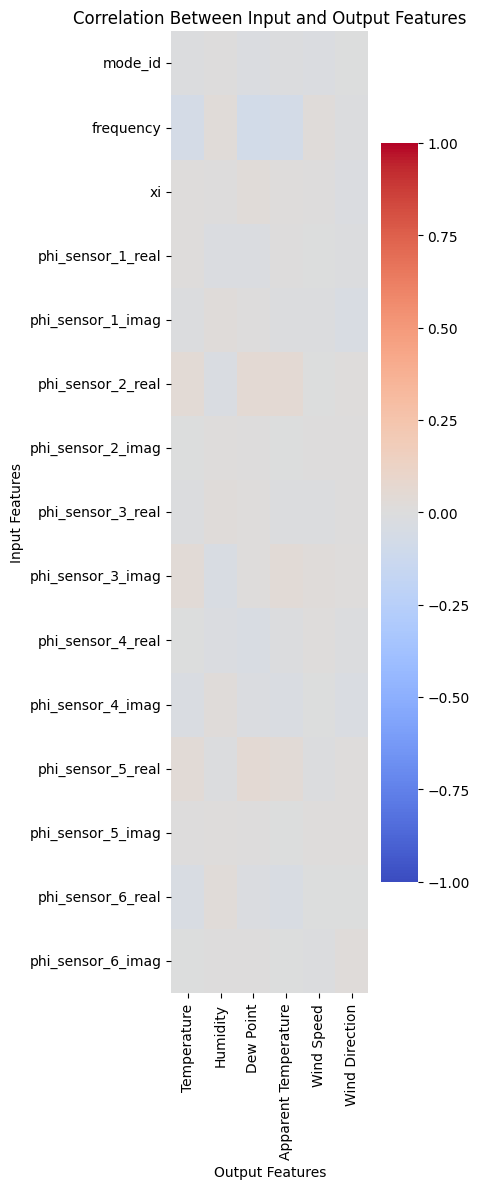

In [5]:
fig = plot_correlation(df_modeshapes, weather_df, annot=False)

### Filter modes and features

In [6]:
# selecting modes to use
modes = [1,2,3]

# selecting environmental effects to use
X_cols = ['Temperature', 'Humidity']

# choose from: frequency, frequency+modeshapes, modeshapes, or custom list of columns
y_cols = 'frequency+modeshapes'

X, y, Q, QoI_names = select_cols(modeshapes_df, modes, X_cols, y_cols)
y, QoI_names, const_cols = remove_constant_columns(y, QoI_names) # removing constant columns

### For training and sensitivity analysis

In [7]:
Q = utils.get_simparamset_from_data(X)
QoI_names = y.columns.to_list()

max_index = 1
QoI_param = 'frequency_mode_1' # Quantity of Interest parameter

subtracted_effects = ['Temperature', 'Humidity']

### For update

In [8]:
nwalkers = 64
nburn = 800
niter = 200

sigma = y.std(axis=0) # standard deviation of the data
E = utils.generate_stdrn_simparamset(sigma.values)

# Train model

### Model configurations

In [9]:
config_dnn = {  
                'init_config' : {
                    'layers': [
                        {'neurons': 32, 'activation': 'relu', 'dropout': 0.1},
                        {'neurons': 64, 'activation': 'sigmoid', 'dropout': 0.1},
                        {'neurons': 128, 'activation': 'relu', 'dropout': None},
                        ],
                    'outputAF': 'tanh'
                    },
                'train_config' : {
                    'optimizer': 'Adam',
                    'loss': 'MSE',
                    'epochs': 200,
                    'batch_size': 32,
                    'k_fold': None,
                    'early_stopping': {
                        'patience': 50,
                        'min_delta': 0.0001}
                    }
}

config_gbt = {
    'init_config' : {
        'gbt_method': 'xgboost'
    },
    'train_config' : {
        'max_depth': 6,
        'num_of_iter': 250,
        'k_fold': 5
        }
}

config_gpce = {
    'init_config' : {
    'p' : 2
    }, 
    'train_config' : {
        'k_fold': 5
        }
}
config_linreg = {
    'init_config': {},
    'train_config': {}
}

config = {'LinReg': config_linreg, 'DNN': config_dnn, 'GBT': config_gbt, 'gPCE': config_gpce}

In [10]:
split_config = {
        'train_test_ratio': 0.8, 
        'random_seed': 1997,
        'split_type': 'no_shuffle'
}

## LinReg model

In [11]:
method = 'LinReg'

In [12]:
# Initialize surrogate model
model = DataDrivenModel(Q, QoI_names, method, **config.get(method)['init_config'])
# Split data into training and testing sets
X_train, X_test, y_train, y_test = model.train_test_split(X, y, **split_config)

# fill missing data
for col in QoI_names:
    y_train[col] = y_train[col].fillna(y_train[col].mean())
    y_test[col] = y_test[col].fillna(y_train[col].mean())

# Train the model
model.train(X_train, y_train, **config.get(method)['train_config'])
metrics, agg_metrics = model.evaluate_model(y_train, X_test, y_test, verbose=False)
print('\nEvaluation metrics:')
metrics.head()

----- Training started for 'LinReg' model -----
Average train loss: 0.08520393429375, Average valid loss: 0.08322653904828
----- Training ended for 'LinReg' model -----



Evaluation metrics:


,Kendall_tau,Pearson,Spearman,MSE,MAE,RMSE,STD_of_label,NRMSE,NMAE,rel_RMSE,summed_metric
Output_Name,,,,,,,,,,,
frequency_mode_1,0.220135,0.433290,0.321426,0.004849,0.050904,0.069635,0.041390,0.279874,0.204592,1.682433,-0.235861
phi_sensor_1_real_mode_1,0.275229,0.259819,0.388141,0.000638,0.015127,0.025268,0.020812,0.094250,0.056422,1.214112,-0.096974
phi_sensor_1_imag_mode_1,0.097369,0.065693,0.141496,0.000362,0.011708,0.019021,0.020889,0.052890,0.032556,0.910576,-0.202006
phi_sensor_2_real_mode_1,0.104382,0.121155,0.154760,0.001775,0.030821,0.042135,0.041887,0.121861,0.089137,1.005917,-0.208540
phi_sensor_2_imag_mode_1,0.222423,0.337337,0.321902,0.001987,0.035599,0.044575,0.040848,0.146052,0.116643,1.091249,-0.069862


In [13]:
# get mean and variance of surrogate model
mean, var = model.get_mean_and_var()
mean, var

(array([ 3.88486549e+00,  5.25171187e-01, -2.62564800e-02,  1.22391748e-01,
        -9.48860927e-02,  4.28828242e-01, -1.61642014e-02,  9.98760855e-01,
        -8.54446788e-05,  1.83796638e-01, -1.98590001e-01,  8.75021268e-01,
        -6.62172275e-03,  5.22958284e+00,  3.57109816e-01,  3.89269022e-02,
         5.75227140e-01, -1.35256460e-02, -2.05629819e-01, -1.73486610e-02,
         5.53073776e-01,  7.74747626e-02,  9.97528607e-01, -9.56348388e-05,
        -5.50473088e-01,  2.14684833e-02,  5.83109875e+00, -5.01571899e-02,
        -3.48717387e-02,  6.02635106e-02,  1.23342386e-02,  7.01073752e-02,
         2.36892467e-02, -8.20088089e-02, -6.54894888e-02,  1.35546658e-01,
         2.78779427e-02,  1.03542029e-01,  6.04133295e-02]),
 array([1.84784464e-03, 8.78676355e-05, 1.24820013e-06, 1.44262214e-04,
        4.90939343e-05, 6.60177905e-05, 2.04215473e-05, 7.04559746e-07,
        2.31900908e-07, 6.14209084e-04, 1.39928417e-04, 5.51976448e-05,
        1.57713769e-05, 3.29002365e-03,

In [14]:
q_df = X_test.iloc[23]
q_df = pd.DataFrame([q_df], columns=model.Q.param_names())
z_m_df = pd.DataFrame([y_test.iloc[23]], columns=QoI_names)

## Sobol sensitivities

In [15]:
# set max_index for Sobol sensitivity analysis
max_index = 3
partial_variance, sobol_index = model.get_sobol_sensitivity(max_index)

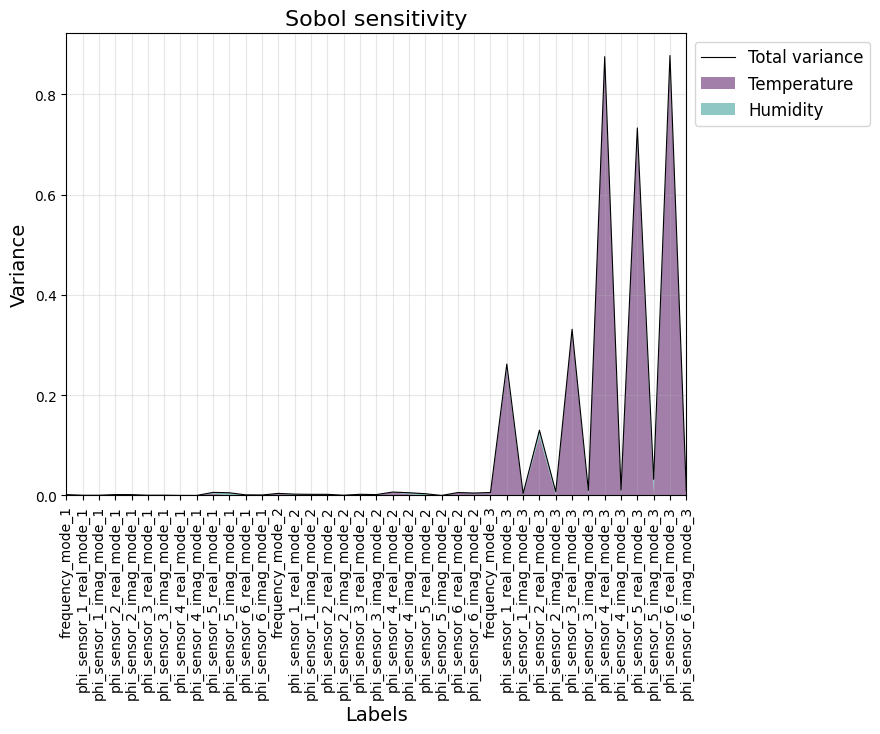

In [16]:
# Plot Sobol Sensitivity Index
# The 'plot_sobol_sensitivity' method generates a plot of Sobol Sensitivity indices, which quantify 
# the contribution of each input parameter to the output uncertainty. 
# - max_index: Specifies the maximum index of parameters to consider in the plot.
# - param_name: The name of the quantity of interest (QoI) for which sensitivity is being calculated ('frequency_mode_1' in this case).
fig = model.plot_sobol_sensitivity(y_train, max_index)

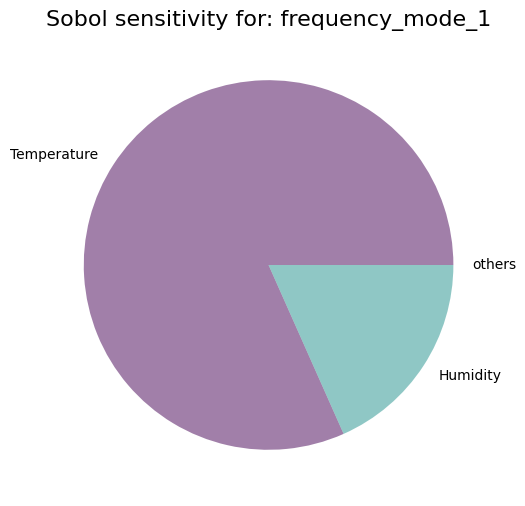

In [17]:
fig = model.plot_sobol_sensitivity(y_train, max_index=max_index, param_name=QoI_param)

## SHAP values

In [18]:
# Calculate SHAP (Shapley Additive Explanations) values
# The 'get_shap_values' method computes the SHAP values for the model's test data (model.X_test). 
# SHAP values explain the contribution of each input feature to the prediction for each test sample.
# SHAP values help to interpret the model's decisions and understand the impact of each input parameter on the output.
shap_values = await model.get_shap_values(X_test)

Message: sample size for shap values is set to 100.


  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

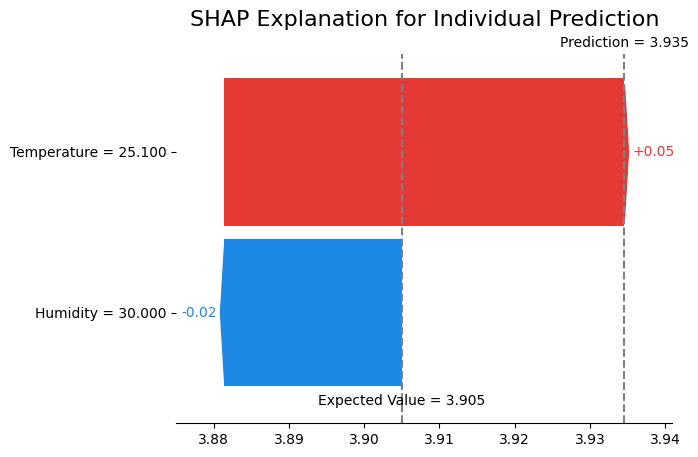

In [19]:
# Plot SHAP Single Waterfall Plot
# The 'plot_shap_single_waterfall' method generates a SHAP waterfall plot for a single test sample, 
# visualizing how each feature contributes to the model's prediction for that sample.
# - q: A DataFrame containing the sample data (e.g., a specific parameter set) for which the SHAP values are calculated.
# - param_name: The name of the quantity of interest (QoI) being analyzed ('frequency_mode_1' in this case).
# The SHAP waterfall plot shows the cumulative effect of each feature on the model's prediction, helping to interpret individual predictions.
fig = await model.plot_shap_single_waterfall(X_test, q=q_df, param_name=QoI_param)

  0%|          | 0/1 [00:00<?, ?it/s]

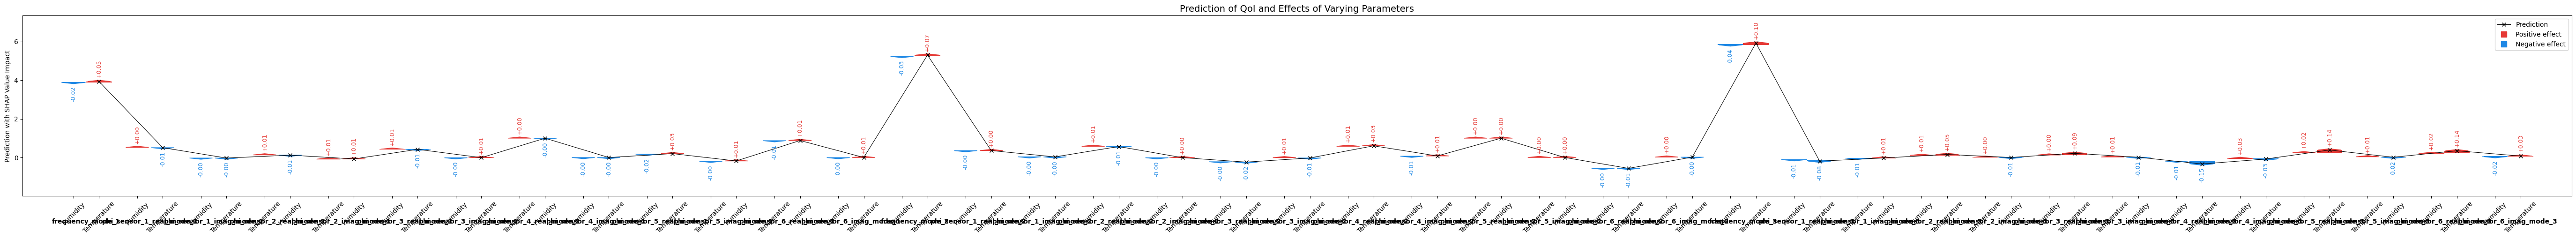

In [20]:
fig = await model.plot_shap_multiple_waterfalls(X_test, q=q_df)

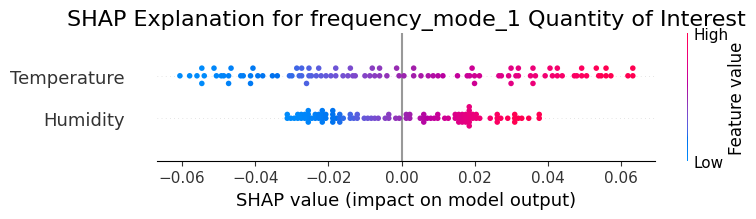

In [21]:
# Plot SHAP Beeswarm Plot
# The 'plot_shap_beeswarm' method generates a SHAP beeswarm plot, which visualizes the distribution of SHAP values
# for a range of test samples, showing the impact of each feature on the model’s predictions.
# - q: The test data (model.X_test.iloc[:100]) is selected for which SHAP values are calculated and visualized.
# - param_name: The name of the quantity of interest (QoI) for which SHAP values are computed ('frequency_mode_1' in this case).
# The SHAP beeswarm plot shows how different input features influence the predictions across multiple samples,
# helping to understand the global feature importance and the relationships between features and the target.
fig = await model.plot_shap_beeswarm(X_test, param_name=QoI_param)

## Effects

Message: sample size for shap values is set to 100, which is the number of samples.


  0%|          | 0/100 [00:00<?, ?it/s]

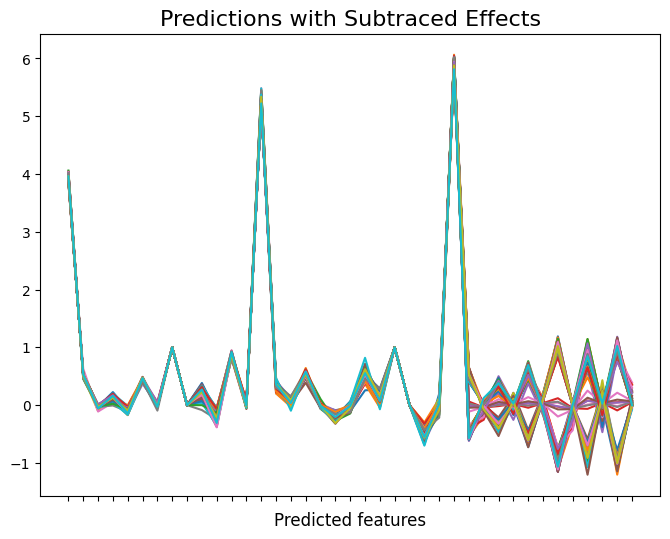

In [22]:
effects = await model.subtract_effects(X_test.iloc[:100], y_test.iloc[:100], subtracted_effects)
fig = await model.plot_effects(effects, xticks=False)

Message: sample size for shap values is set to 1576, which is the number of samples.


  0%|          | 0/1576 [00:00<?, ?it/s]

Message: sample size for shap values is set to 1, which is the number of samples.


  0%|          | 0/1 [00:00<?, ?it/s]

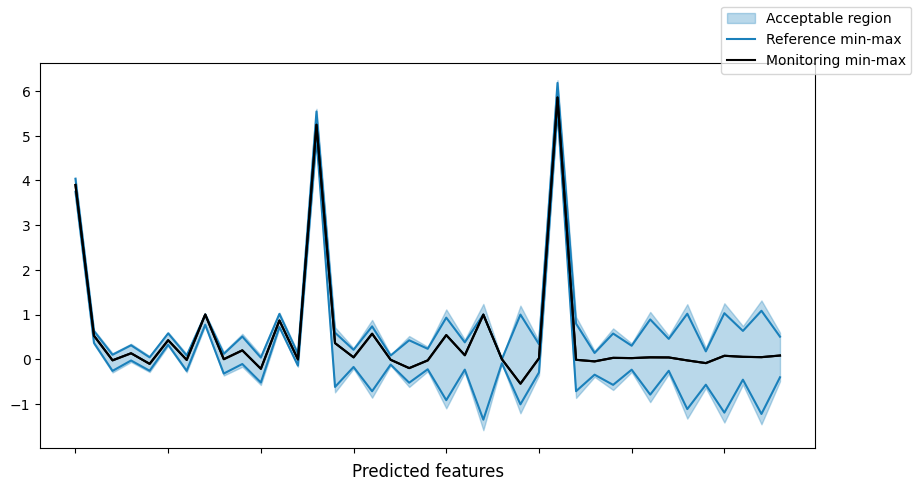

In [23]:
fig, alert, remained_effects_df, error_ratio, problematic_rows, reference_statistics, monitoring_statistics = await model.plot_subtract_effects_and_alert(X_train, y_train, q_df, z_m_df, subtracted_effects[1:], xticks=False)

## Update

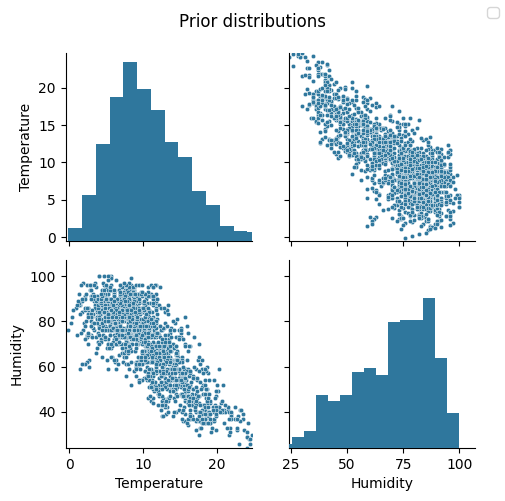

In [24]:
fig = utils.plot_prior(model, X_train)

MCMC creating
Burning period


100%|██████████| 800/800 [02:36<00:00,  5.12it/s]


MCMC running


100%|██████████| 200/200 [00:34<00:00,  5.79it/s]


--- 190.82509469985962 seconds ---


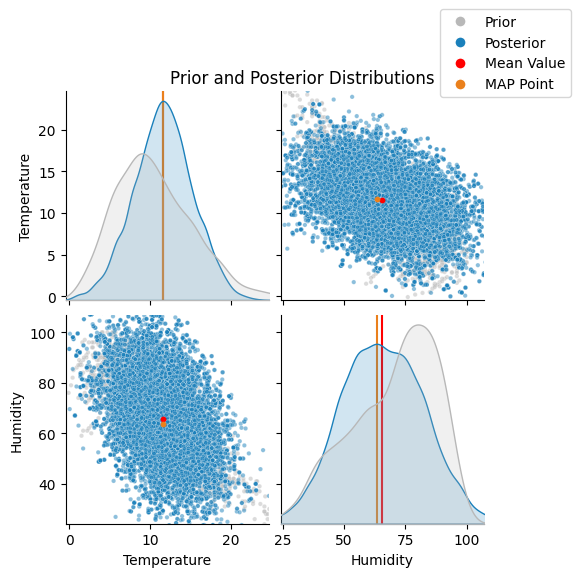

In [25]:
DT = DigitalTwin(model, E)
DT.update(z_m_df, nwalkers=nwalkers, nburn=nburn, niter=niter)
DT.get_mean_and_var_of_posterior()
gpc_map = DT.get_MAP()
fig = utils.plot_MCMC(model, X_train, DT, nwalkers=nwalkers, map_point=gpc_map)

## Comparing models

In [26]:
# selecting modes to use
modes = [0,1,2,3,6]

# selecting environmental effects to use
X_cols = ['Temperature', 'Humidity']

# choose from: frequency, frequency+modeshapes, modeshapes, or custom list of columns
# here using only frequency columns
y_cols = 'frequency'

X, y, Q, QoI_names = select_cols(modeshapes_df, modes, X_cols, y_cols)

In [27]:
model_types = ['LinReg', 'DNN', 'GBT', 'gPCE']
metrics_all = []

for model_type in model_types:
    model = DataDrivenModel(Q, QoI_names, model_type, **config.get(model_type)['init_config'])
    X_train, X_test, y_train, y_test = model.train_test_split(X, y, **split_config)

    # fill missing data
    for col in QoI_names:
        y_train[col] = y_train[col].fillna(y_train[col].mean())
        y_test[col] = y_test[col].fillna(y_train[col].mean())

    model.train(X_train, y_train, **config.get(model_type)['train_config'])
    metrics, agg_metrics = model.evaluate_model(y_train, X_test, y_test, verbose=False)
    metrics['Model Name'] = model_type
    metrics = metrics.reset_index()
    metrics_all.append(metrics)

metrics = pd.concat(metrics_all, axis=0)
col = metrics.pop('Model Name')
metrics.insert(0, 'Model Name', col)
print('\nEvaluation metrics:')
metrics

----- Training started for 'LinReg' model -----
Average train loss: 0.00256562559713, Average valid loss: 0.00285463550221
----- Training ended for 'LinReg' model -----
Using device: cpu
----- Training started for 'DNN' model -----
Epoch [0/200], train loss: 0.2046, validation loss: 0.0760
Epoch [50/200], train loss: 0.0084, validation loss: 0.0096
Epoch [100/200], train loss: 0.0083, validation loss: 0.0095
Early stopping triggered after 111 epochs!
Training stopped early. Restoring best model (monitored val_loss = 0.0093).
Average train loss: 0.00826952564933, Average valid loss: 0.00936295339813
----- Training ended for 'DNN' model -----
----- Training started for 'GBT' model -----
Fold 1/5
Fold 2/5
Fold 3/5
Fold 4/5
Fold 5/5
Average train loss: 0.00049157159105, Average valid loss: 0.00366142253754
----- Training ended for 'GBT' model -----
----- Training started for 'gPCE' model -----
Fold 1/5
Fold 2/5
Fold 3/5
Fold 4/5
Fold 5/5
Average train loss: 0.00254560228881, Average valid 

,Model Name,Output_Name,Kendall_tau,Pearson,Spearman,MSE,MAE,RMSE,STD_of_label,NRMSE,NMAE,rel_RMSE,summed_metric
0,LinReg,frequency_mode_0,-0.134486,-0.017777,-0.170395,0.002891,0.024096,0.053767,0.035578,0.106394,0.047681,1.511235,-0.611297
1,LinReg,frequency_mode_1,0.220135,0.433290,0.321426,0.004849,0.050904,0.069635,0.041390,0.279874,0.204592,1.682433,-0.235861
2,LinReg,frequency_mode_2,0.012175,0.159035,0.015673,0.009445,0.067810,0.097188,0.064308,0.164563,0.114819,1.511290,-0.441469
3,LinReg,frequency_mode_3,0.146630,0.358702,0.215413,0.014201,0.088853,0.119167,0.077061,0.241356,0.179958,1.546407,-0.275221
4,LinReg,frequency_mode_6,0.018651,0.066737,0.026901,0.004111,0.029834,0.064120,0.057088,0.073616,0.034253,1.123164,-0.336958
0,DNN,frequency_mode_0,-0.117417,-0.018537,-0.148766,0.003020,0.023369,0.054954,0.035578,0.108743,0.046243,1.544601,-0.609774
1,DNN,frequency_mode_1,0.219036,0.414929,0.318860,0.004876,0.050612,0.069830,0.041390,0.280656,0.203417,1.687137,-0.244771
2,DNN,frequency_mode_2,0.028227,0.168341,0.039365,0.009502,0.066324,0.097478,0.064308,0.165054,0.112303,1.515799,-0.426622
3,DNN,frequency_mode_3,0.150407,0.342498,0.221751,0.014495,0.091101,0.120393,0.077061,0.243839,0.184513,1.562319,-0.282554
4,DNN,frequency_mode_6,0.011044,0.032547,0.017714,0.004425,0.033802,0.066524,0.057088,0.076376,0.038808,1.165271,-0.367989


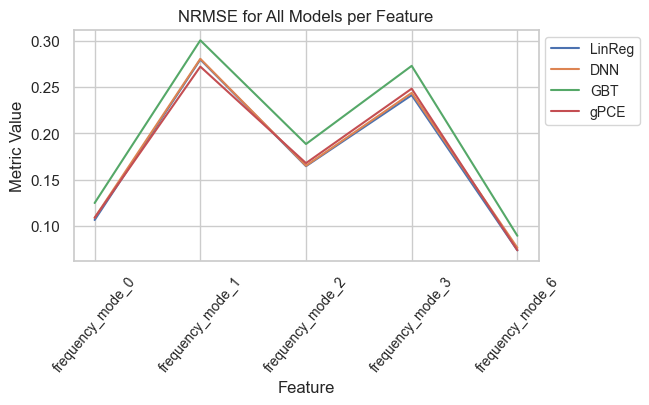

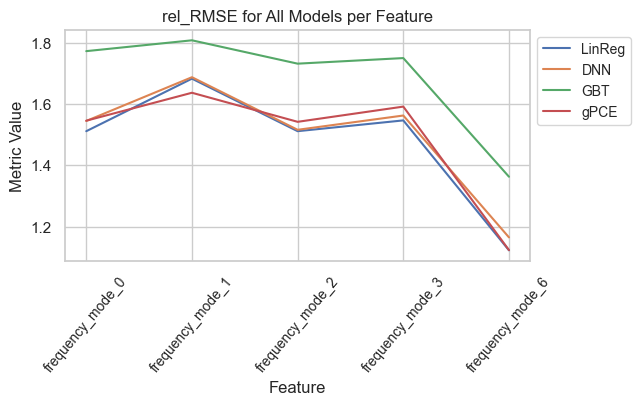

In [28]:
# metrics visualization
sns.set(style="whitegrid")
metric_cols = ['NRMSE', 'rel_RMSE']
for metric in metric_cols:
    plt.figure(figsize=(6, 3))
    sns.lineplot(data=metrics, x='Output_Name', y=metric, hue='Model Name')
    plt.xticks(rotation=50, fontsize=10)
    plt.ylabel('Metric Value')
    plt.xlabel('Feature', fontsize=12)
    plt.title(f'{metric} for All Models per Feature')
    plt.legend(ncol=1, fontsize='small', bbox_to_anchor=(1,1))
plt.show()